# [기초-실습] 통계 101×데이터 분석: (1-3장): 통계분석의 기초

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [1]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Fetched 10.3 MB in 1s (8,218 kB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories cur

In [2]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 기초통계량 계산

**📘 문제**

- 온라인 쇼핑몰 고객 1,000명을 대상으로 1점부터 10점 사이의 만족도 조사를 실시했습니다.
  이 데이터를 바탕으로 고객 만족도의 **중심 경향성**과 **분포 특성**을 파악해 봅시다.

In [3]:
# 데이터 생성
np.random.seed(2025)
satisfaction = np.random.normal(7.5, 1.5, 1000)
satisfaction = np.clip(satisfaction, 1, 10)
df1 = pd.DataFrame({'score': satisfaction})

**📌 아래를 수행해 보세요:**

- 평균, 중앙값, 최빈값, 표준편차를 계산해 봅시다.
- 히스토그램을 그리고 평균과 중앙값 선으로 표시해 봅시다.
- 데이터의 분포 형태를 해석한 후, 마케팅 전략 수립에 어떻게 활용할 수 있을지 생각해 봅시다.

평균: 7.43
중앙값: 7.42
최빈값:  7.0
표준편차: 1.39



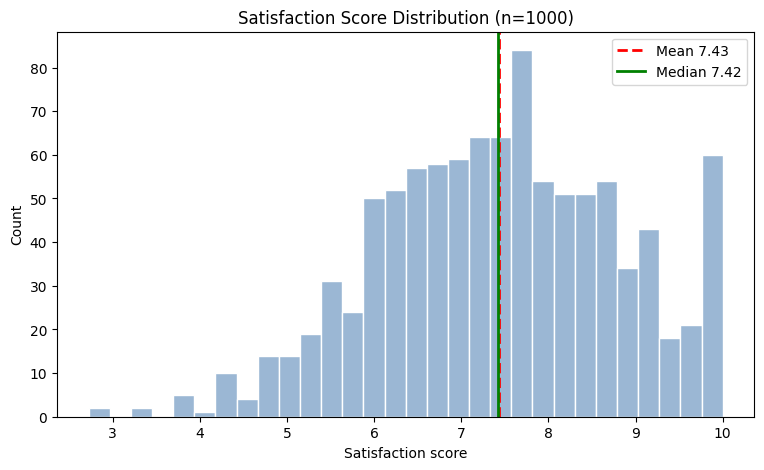

In [4]:
# 아래를 수행해 보세요:
# [문제 1] 여기에 코드를 작성해주세요.

x = df1["score"]

print(f'평균: {x.mean():.2f}')
print(f'중앙값: {x.median():.2f}')
print("최빈값: ", x.round().mode()[0])
print(f'표준편차: {x.std():.2f}')

print()

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(x, bins=30, color='#9bb7d4', edgecolor='white')
ax.axvline(x.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean {x.mean():.2f}')
ax.axvline(x.median(), color='green', linestyle='-', linewidth=2, label=f'Median {x.median():.2f}')
ax.set_xlabel('Satisfaction score')
ax.set_ylabel('Count')
ax.set_title('Satisfaction Score Distribution (n=1000)')
ax.legend()
plt.show()

In [ ]:
3. 분포 형태 해석

거의 대칭인 종 모양입니다. 평균(7.43)과 중앙값(7.42)의 차이가 0.01에 불과합니다. 왜도도 −0.17로, 아주 약하게만 왼쪽으로 꼬리가 깁니다. 따라서 평균을 이 집단의 대표값으로 써도 무리가 없습니다.

전반적으로 만족도가 높습니다. 응답의 절반이 7.4점 이상입니다. 중간 50%(사분위 범위)는 6.5~8.4점에 몰려 있습니다.

10점에 쏠림이 있습니다. 히스토그램 오른쪽 끝에 막대가 튀어나와 있습니다. 실제 설문이라면 “10점 이상으로 만족한” 사람들이 척도 상한에 막혀 구분되지 않는 상황, 즉 천장 효과입니다.

불만족층은 소수입니다. 왼쪽 꼬리가 3점 근처까지 이어지지만, 5점 이하(반올림 기준)는 85명으로 8.5% 수준입니다.

4. 마케팅 전략 활용

정수로 반올림한 점수로 고객을 나누면 전략을 세우기 쉬워집니다. NPS(순추천지수) 방식을 빌려 오면 다음과 같습니다.

그룹	점수	비율	전략 방향
충성 고객	9~10점	23.4%	추천 프로그램, 리뷰·후기 요청, VIP 혜택으로 입소문 확산
중립 고객	7~8점	50.8%	가장 큰 집단. 업셀링, 개인화 혜택, 멤버십으로 충성 고객 전환 유도
이탈 위험 고객	6점 이하	25.8%	불만 원인 조사(후속 설문, 인터뷰), 보상 쿠폰, 고객센터 집중 관리

**🧠 데이터를 어떻게 읽을까요?**

1. 평균과 중앙값 사이의 차이는 어느 정도인가요?
   - 두 값이 비슷하다면, 이 데이터는 어떤 분포 형태일 가능성이 있을까요? (예: 대칭형, 정규분포 등)
   - 두 값의 차이가 크다면, 그 이유는 무엇일까요?
   - 어떤 값들이 평균을 끌어내리거나 끌어올렸을까요?

2. 최빈값이 평균보다 낮은 경우, 낮은 점수를 준 고객이 많다는 뜻일 수 있습니다. 이 경우 데이터 분포는 어느 쪽으로 치우쳐 있을까요?
   - 반대로 최빈값이 평균보다 높은 경우에는 어떤 해석이 가능할까요? 이럴 때 분포가 어떻게 달라질 수 있을까요?

3. 이 데이터를 바탕으로 고객 만족도를 높이기 위한 마케팅 전략에는 어떤 것들이 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 1] 여기에 의견을 작성해주세요.

1. 평균과 중앙값 사이의 차이가 0.01이다.
    - 거의 대칭인 종 모양 형태이다.
    - 두 값의 차이가 크다면, 
    한쪽으로 치우친 분포이거나 극단값이 있기 때문입니다.
    평균은 모든 값을 더해 나누므로 극단값에 끌려가지만,
    중앙값은 순서상 가운데 값이라 극단값의 영향을 
    거의 받지 않습니다. 
    예를 들어 대부분 8~9점인데 1~2점을 준 고객이 몇 명
    있으면, 평균만 아래로 끌려 내려가 중앙값보다 
    낮아집니다.
    - 제일 왼쪽에 있는 값들이 평균값을 내리고 clip으로 
    짤려나간 숫자들로 평균이 낮아졌을 것이다.

2. 최빈값이 평균보다 낮으면 분포는 오른쪽으로 꼬리가 긴
(양의 왜도) 형태입니다. 
    봉우리가 낮은 점수 쪽에 있다는 뜻이므로, 
다수 고객이 만족하지 못하고 있다는 신호입니다. 
평균만 보면 실제보다 상황이 좋아 보일 수 있어 주의해야
합니다.

최빈값이 평균보다 높으면 분포는 왼쪽으로 
꼬리가 긴(음의 왜도) 형태입니다. 대부분의 고객은 
만족하지만, 소수의 강한 불만 고객이 평균을 깎아 
먹는 상황입니다. 이때는 평균보다 그 소수 불만층이 
누구인지가 더 중요한 정보입니다.

    3.
측정 방식 개선하기. 10점에 응답이 몰리는 천장 효과가 있으므로, 다음 설문에 재구매 의향이나 추천 의향 문항을 추가하면 최상위 고객을 더 세밀하게 구분할 수 있습니다.

# 문제 2. 평균 vs 중앙값 비교

**📘 문제**

- A지역과 B지역의 연봉 데이터를 비교해 봅시다.
- B 지역에는 일부 고소득자가 포함되어 있습니다.

In [5]:
# 데이터 생성
np.random.seed(2025)

# A 지역: 평균 300, 표준편차 50
region_a = np.random.normal(300, 50, 100)

# B 지역: 일반 소득자 + 극단적인 고소득자 포함
region_b = np.concatenate([
    np.random.normal(280, 40, 95),    # 일반 소득자 95명
    np.random.normal(1500, 200, 5)    # 고소득자 5명
])

df2 = pd.DataFrame({
    'region': ['A'] * 100 + ['B'] * 100,
    'salary': np.concatenate([region_a, region_b])
})

**📌 아래를 수행해 보세요:**

- 각 지역의 평균 연봉과 중앙값을 구해 봅시다.
- 지역별 박스플롯(Boxplot)을 그려서 분포의 차이를 시각적으로 확인해 봅시다.

              mean      median
region                        
A       292.506637  294.324483
B       347.594909  287.347488



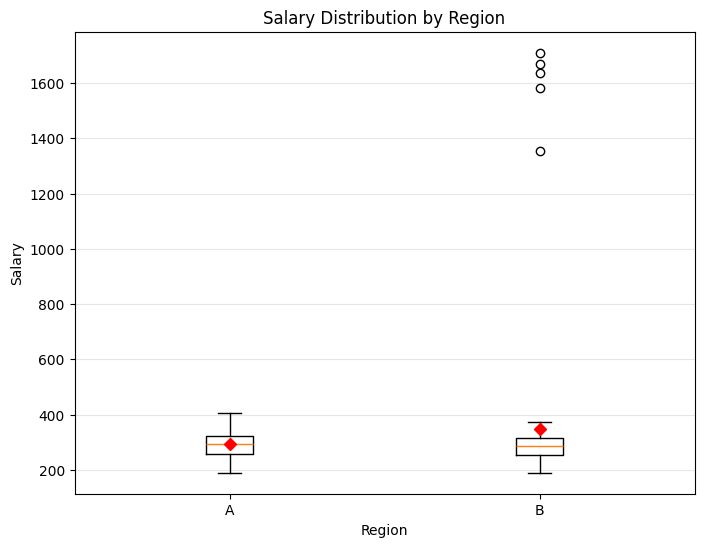

In [6]:
# 아래를 수행해 보세요:
# [문제 2] 여기에 코드를 작성해주세요.

result = df2.groupby('region')['salary'].agg(["mean", "median"])
print(result)
print()
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
data = [df2[df2['region'] == r]['salary'] for r in ['A', 'B']]
ax.boxplot(data, tick_labels=['A', 'B'], showmeans=True,
           meanprops=dict(marker='D', markerfacecolor='red', markeredgecolor='red'))
ax.set_xlabel('Region')
ax.set_ylabel('Salary')
ax.set_title('Salary Distribution by Region')
ax.grid(axis='y', alpha=0.3)
plt.show()


region
A    100
B     95
Name: count, dtype: int64


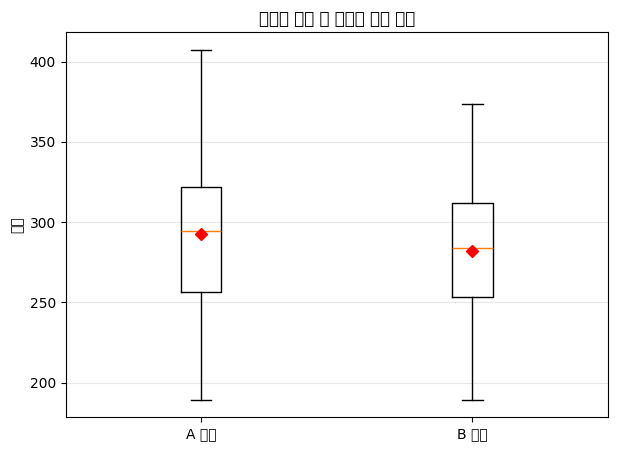

In [16]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'   # 맥은 'AppleGothic'

# 지역별로 IQR 기준 이상치 제거
def remove_outliers(s):
    Q1 = s.quantile(0.25)
    Q3 = s.quantile(0.75)
    IQR = Q3 - Q1
    return s[(s >= Q1 - 1.5 * IQR) & (s <= Q3 + 1.5 * IQR)]

df2_clean = (df2.groupby('region')['salary']
                .apply(remove_outliers)
                .reset_index(level=0))

print(df2_clean['region'].value_counts())   # A 100명, B 95명

# 박스플롯
fig, ax = plt.subplots(figsize=(7, 5))
data = [df2_clean[df2_clean['region'] == r]['salary'] for r in ['A', 'B']]
ax.boxplot(data, tick_labels=['A 지역', 'B 지역'], showmeans=True,
           meanprops=dict(marker='D', markerfacecolor='red', markeredgecolor='red'))
ax.set_ylabel('연봉')
ax.set_title('이상치 제거 후 지역별 연봉 분포')
ax.grid(axis='y', alpha=0.3)
plt.show()

In [ ]:
df2 = pd.DataFrame({
    'region': ['A'] * 100 + ['B'] * 100,
    'salary': np.concatenate([region_a, region_b])
})

**🧠 데이터를 어떻게 읽을까요?**

1. A 지역과 B 지역의 평균 연봉은 어떻게 다른가요?
   - 두 지역의 평균 차이가 의미하는 바는 무엇인가요?
   - 고소득자가 있는 지역의 평균은 어떤 영향을 받을까요?

2. 중앙값은 어떠한가요?
   - 평균과 비교했을 때, 중앙값이 더 낮거나 높다면 어떤 해석이 가능할까요?

3. 극단값(고소득자)의 영향은 어디에서 더 크게 나타날까요?
   - 평균과 중앙값 중 어떤 지표가 극단값에 더 민감한가요?

4. 박스플롯을 통해 어떤 점을 관찰할 수 있나요?
   - 이상치(Outlier)는 어떻게 표시되나요?
   - 두 지역의 분포 폭(사분위 범위)은 어떻게 다른가요?

5. 평균만 보고 판단했을 때 생길 수 있는 오해는 무엇인가요?
   - 어떤 경우에는 중앙값이 더 유용한 지표일 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 2] 여기에 의견을 작성해주세요.
1. A 지역과 B 지역의 평균 연봉은 어떻게 다른가요?

▸두 지역의 평균 차이가 의미하는 바는 무엇인가요?
b지역의 평균이 a지역보다 약 55정도 더 높다. 
b지역이 평균적으로 a지역보다 더 많이 번다는 것으로 읽을 수 있다. 
▸고소득자가 있는 지역의 평균은 어떤 영향을 받을까요?
b지역의 고소득자 5명은 소수에 불과하지만 이들 때문에 평균이 올라갔다.

2. 중앙값은 어떠한가요?

▸평균과 비교했을 때, 중앙값이 더 낮거나 높다면 어떤 해석이 가능할까요?
평균보다 중앙값이 낮거나 높을 때의 해석은 다음과 같습니다.

중앙값 < 평균 (B 지역): 높은 쪽에 극단값이 있어 평균이 끌려 올라간 상태입니다. 오른쪽으로 꼬리가 긴 분포이며, 대다수 사람은 평균보다 적게 법니다.
중앙값 > 평균: 낮은 쪽에 극단값이 있어 평균이 끌려 내려간 상태입니다. 왼쪽으로 꼬리가 긴 분포입니다.
중앙값 ≈ 평균 (A 지역): 대칭에 가까운 분포로, 평균을 대표값으로 써도 괜찮습니다.

1)b지역처럼 평균이 더 높다는 것은 높은쪽에 극단값이 있어 평균이 끌려 올라간 상태.
오르쪽으로 꼬리가 긴 분포이며 대다수 사람은 평균보다 적게 번다고 해석 됨 
2) 평균보다 중앙값이 높다는 것은 낮은 쪽에 극단값이 있어 평균이 끌려 내려간 상태.
   왼쪽으로 꼬리가 긴 분포

3. 극단값(고소득자)의 영향은 어디에서 더 크게 나타날까요?

▸평균과 중앙값 중 어떤 지표가 극단값에 더 민감한가요?
 평균이 극단값이 더 큰 영향을 받는다. 평균은 값의 크기를 모두 반영하기때문에
중앙값은 순서상 가운데 위치만 확인

4. 박스플롯을 통해 어떤 점을 관찰할 수 있나요?

▸이상치(Outlier)는 어떻게 표시되나요?
b 위쪽의 동그라미 5개가 이상치가 보인다. 
▸두 지역의 분포 폭(사분위 범위)은 어떻게 다른가요?
a와b 둘 다 가운데 50%의 소득 범위가 비슷하게 위치해 있다. 

추가) 평균(빨간 마름모)가 상자 바깥에 위치. b주민 75% 이상이 평균보다 적게 번다는 뜻

5.평균만 보고 판단했을 때 생길 수 있는 오해는 무엇인가요?
평균만 보고 판단 했을 때 b지역이 a지역보다 부유하다고 해석할 수 있음. 

▸어떤 경우에는 중앙값이 더 유용한 지표일 수 있을까요?
소수의 극단값이 섞이기 쉬운 데이터에 유용
1. 소득 연봉, 집값 전세값(일부 고가 주택이 평균을 올림)


In [ ]:
# 아래를 수행해 보세요:


# 문제 3. 이상값과 분산 비교

**📘 문제**

- 1반과 2반의 시험 점수 분포를 비교해 봅시다.
- 2반에는 극단적인 이상값(예: 부정행위로 0점)이 포함되어 있습니다.

In [7]:
# 데이터 생성
np.random.seed(2025)  # 재현 가능성을 위해 시드 고정

# 1반: 평균 75, 표준편차 8
class1 = np.random.normal(75, 8, 30)

# 2반: 일반 학생 + 이상값(0점, 130점)
class2 = np.concatenate([
    np.random.normal(75, 15, 28),  # 일반 학생
    [0, 130]                       # 극단적인 이상값
])

df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

**📌 아래를 수행해 보세요:**

1. 각 반의 평균, 표준편차, 최소/최대값을 계산해 봅시다.
2. 박스플롯을 사용하여 두 반의 분포 차이를 시각적으로 비교해 봅시다.
3. 이상값이 통계 지표에 어떤 영향을 주는지 생각해 봅시다.

        mean    std    min     max
class                             
1반    75.72   7.06  60.69   92.18
2반    73.73  22.34   0.00  130.00



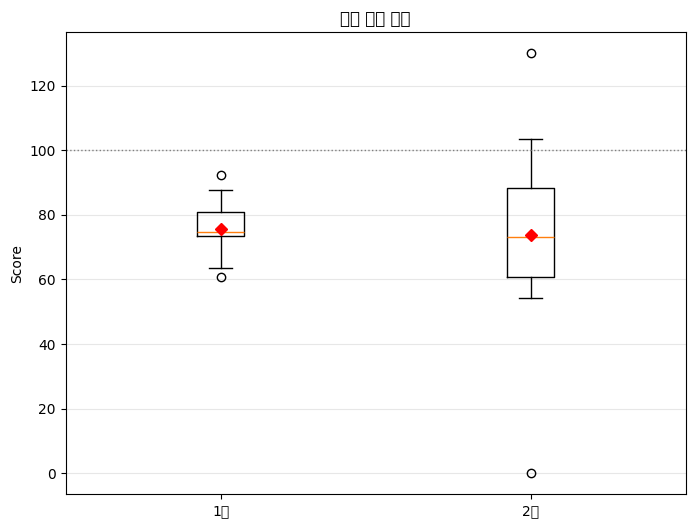

In [8]:
# 아래를 수행해 보세요:
# [문제 3] 여기에 코드를 작성해주세요.

result3 = df3.groupby('class')['score'].agg(["mean", "std", "min", "max"]).round(2)
print(result3)
print()

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
data = [df3[df3['class'] == c]['score'] for c in ['1반', '2반']]
ax.boxplot(data, tick_labels=['1반', '2반'], showmeans=True,
           meanprops=dict(marker='D', markerfacecolor='red', markeredgecolor='red'))
ax.axhline(100, color='gray', linestyle=':', linewidth=1)   # 만점 기준선
ax.set_ylabel('Score')
ax.set_title('반별 점수 분포')
ax.grid(axis='y', alpha=0.3)
plt.show()

In [ ]:
df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

**🧠 데이터를 어떻게 읽을까요?**

1. 어떤 반의 점수 분산이 더 크고, 왜 그럴까요?
   - 점수 분포의 퍼짐 정도는 어떤 지표로 확인할 수 있을까요?
   - 이상값이 포함되면 표준편차나 범위는 어떻게 달라질까요?

2. 이상값이 있는 반의 평균은 어떤 영향을 받았나요?
   - 극단적으로 낮거나 높은 점수가 평균을 끌어내리거나 끌어올렸나요?
   - 평균과 중앙값의 차이가 의미하는 바는 무엇인가요?

3. 박스플롯을 통해 이상값은 어떻게 드러나나요?
   - 이상값(outlier)은 박스플롯에서 어떤 형태로 나타나나요?
   - 두 반의 박스(사분위 범위)는 어떻게 다르게 보이나요?

4. 평균만 보고 평가했을 때 생길 수 있는 오해는 무엇인가요?
   - 예를 들어, 교사가 평균 점수만 보고 2반이 부족하다고 판단한다면?
   - 중앙값이나 표준편차 같은 지표와 함께 분석하는 것은 왜 중요할까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 3] 여기에 의견을 작성해주세요.

1. 어떤 반의 점수 분산이 더 크고, 왜 그럴까요?
- 2반의 분산이 더 크다. 분산은 표준편차의 제곱이므로 1반은 약 50, 2반은 약 499로 10배 가까이 차이가 난다. 2반이 원래부터 1반보다 학생의 표준편차를 크게 설정했고 이상값 2개가 평균에서 멀리 떨어져 분산을 크게 키웠다.
▸점수 분포의 퍼짐 정도는 어떤 지표로 확인할 수 있을까요?
	분산: 평균과의 거리를 제곱해 평균 낸 값
▸이상값이 포함되면 표준편차나 범위는 어떻게 달라질까요?
	이상값이 포함되면 표준편차와 범위가 크게 늘어난다. 2반에서 이상값을 배면 표준편차는 22.3에서 14.7로, 범위는 130에서 49.4로 줄어든다. 범위는 양 끝 값을 그대로 쓰기 대문에 표준편차는 거리를 제곱하기 대문에 멀리 떨어진 값에 민감하다.

2. 이상값이 있는 반의 평균은 어떤 영향을 받았나요?

▸극단적으로 낮거나 높은 점수가 평균을 끌어내리거나 끌어올렸나요?
극단적으로 낮은 값은 평균을 낮게 높은 값은 평균을 끌어올린다.
▸평균과 중앙값의 차이가 의미하는 바는 무엇인가요?
평균과 중앙값이 크게 차이 나지 않으면 이는 분포가 한쪽으로 크게 치우치지 않았다는 의미. 이상값이 있을 대는 평균과 중앙값의 차이가 크게 벌어져 이상값의 존재를 알려준다. 

3. 박스플롯을 통해 이상값은 어떻게 드러나나요?

▸이상값(outlier)은 박스플롯에서 어떤 형태로 나타나나요?
수염 바깥의 동그라미로 표시된다. 
▸두 반의 박스(사분위 범위)는 어떻게 다르게 보이나요?
두 반의 상자는 높이가 크게 다르다. 1반 상자는 납작하고 2반 상자는 길죽하다.
중앙값 선 위치는 비슷하다.
즉, 중심은 같은데 퍼짐이 다른 두 집단으로 볼 수 있다. 

4. 평균만 보고 평가했을 때 생길 수 있는 오해는 무엇인가요?

▸예를 들어, 교사가 평균 점수만 보고 2반이 부족하다고 판단한다면?
판단 근거 약함. 평균 차이는 2점 뿐이고, 중앙값 차이도 1.8이밖에 나지 않는다.
▸중앙값이나 표준편차 같은 지표와 함께 분석하는 것은 왜 중요할까요?
중앙값, 평균: 중심이 어디있는가를 알려줌
표준편차, IQR: 얼마나 퍼져있는지를 알려줌

// 지표마다 보여주는 면이 다르기때문



# 문제 4. IQR 이상값 제거

**📘 문제**

- 앞의 문제에서 2반에는 **극단적인 이상값(예: 매우 낮은 점수)**이 포함되어 있어
  통계 지표, 특히 평균에 큰 영향을 주는 것을 확인했습니다.
- 이번에는 **IQR(사분위 범위)**을 기준으로 이상값을 제거한 뒤, 이상값 제거 전후의 평균을 비교해 봅시다

<br>

**📌 아래를 수행해 보세요:**

- 2반의 점수 데이터를 대상으로 IQR 기준을 사용해 이상값을 판별하고 제거해 봅시다.
- 이상값 제거 전과 제거 후의 평균을 각각 계산해 봅시다.
- 이상값 제거가 평균에 어떤 영향을 주는지 설명해 봅시다.
- 필요하다면 중앙값과도 비교해 봅시다.

In [9]:
# 아래를 수행해 보세요:
# [문제 4] 여기에 코드를 작성해주세요.

# 2반 점수만 추출
class2 = df3[df3['class'] == '2반']['score']

# 사분위수와 IQR 계산
Q1 = class2.quantile(0.25)
Q3 = class2.quantile(0.75)
IQR = Q3 - Q1

# 이상값 기준선
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print(f'Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}')
print(f'정상 범위: {lower:.2f} ~ {upper:.2f}')

# 이상값 확인
outliers = class2[(class2 < lower) | (class2 > upper)]
print('이상값:', outliers.tolist())

# 이상값 제거
class2_clean = class2[(class2 >= lower) & (class2 <= upper)]
print(f'제거 전: {len(class2)}명 → 제거 후: {len(class2_clean)}명')

Q1: 60.75, Q3: 88.37, IQR: 27.61
정상 범위: 19.33 ~ 129.79
이상값: [0.0, 130.0]
제거 전: 30명 → 제거 후: 28명


In [10]:
print(f'제거 전 평균: {class2.mean():.2f}')
print(f'제거 후 평균: {class2_clean.mean():.2f}')
print(f'제거 전 중앙값: {class2.median():.2f}')
print(f'제거 후 중앙값: {class2_clean.median():.2f}')
print(f'제거 전 표준편차: {class2.std():.2f}')
print(f'제거 후 표준편차: {class2_clean.std():.2f}')

제거 전 평균: 73.73
제거 후 평균: 74.35
제거 전 중앙값: 73.00
제거 후 중앙값: 73.00
제거 전 표준편차: 22.34
제거 후 표준편차: 14.73


In [ ]:
# 데이터 생성
np.random.seed(2025)  # 재현 가능성을 위해 시드 고정

# 1반: 평균 75, 표준편차 8
class1 = np.random.normal(75, 8, 30)

# 2반: 일반 학생 + 이상값(0점, 130점)
class2 = np.concatenate([
    np.random.normal(75, 15, 28),  # 일반 학생
    [0, 130]                       # 극단적인 이상값
])

df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

**🧠 데이터를 어떻게 읽을까요?**

1. 이상값 제거 전후 평균은 어떻게 달라졌나요?
   - 평균이 중앙값에 가까워졌나요?
   - 이상값 제거가 평균에 어떤 방향으로 영향을 주었나요?

2. 왜 IQR을 기준으로 이상값을 판단할까요?
   - IQR은 데이터를 어떻게 나누고, 어떤 방식으로 이상값을 정의하나요?
   - 평균이나 표준편차 기준과 비교했을 때 어떤 점이 더 강건할까요?

3. 이상값은 언제 제거하고, 언제 유지해야 할까요?
   - 분석 목적에 따라 이상값은 중요한 정보가 될 수 있습니다.

4. 중앙값과 평균은 각각 어떤 상황에서 더 유용한 지표인가요?
   - 이상값이 있을 때 어떤 지표가 더 신뢰할 수 있나요?
   - 두 지표를 함께 보면 어떤 장점이 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 4] 여기에 의견을 작성해주세요.

1.이상값 제거 전후 평균은 어떻게 달라졌나요?
이상값 제거 후 평균은 조금 올라갔다. 
▸평균이 중앙값에 가까워졌나요?
중앙값에서 조금 더 멀어졌다.
▸이상값 제거가 평균에 어떤 방향으로 영향을 주었나요?
평균을 위로 올렸다. 끌어내리던 0점이 빠진 효과가, 끌어올리던 130점이 빠진 효과보다 컸기 때문입니다
2. 왜 IQR을 기준으로 이상값을 판단할까요?

▸IQR은 데이터를 어떻게 나누고, 어떤 방식으로 이상값을 정의하나요?
IQR의 원리는 다음과 같습니다.

데이터를 크기순으로 정렬해 네 등분합니다. 25% 지점이 Q1, 75% 지점이 Q3입니다.
IQR = Q3 − Q1로, 가운데 50% 데이터가 차지하는 폭입니다.
Q1 − 1.5×IQR보다 작거나 Q3 + 1.5×IQR보다 크면 이상값으로 봅니다.

▸평균이나 표준편차 기준과 비교했을 때 어떤 점이 더 강건할까요?
평균·표준편차 기준보다 강건한 이유는 기준을 정하는 재료에 있습니다. 평균·표준편차 방식은 흔히 "평균 ± 3σ를 벗어나면 이상값"으로 판단하는데, 문제는 찾으려는 이상값이 평균과 표준편차를 이미 오염시킨다는 점입니다.

3.이상값은 언제 제거하고, 언제 유지해야 할까요?
제거하는 경우: 불가능한 값(100점이 만점인데 130점이 나온 경우)
	     측정, 기록 오류(센서 고장, 단위 착오)
유지하는 경우: 실제로 일어난 일이고, 그 자체가 정보일 때
	     0점을 받은 학생: 실제로 응시해서 받은 점수일 수도 있다.
	       고소득자: 실제 존재하는 사람이므로 지우면 실제 소득 구조가 왜곡됨

4.중앙값과 평균은 각각 어떤 상황에서 더 유용한 지표인가요?
중앙값: 한쪽으로 치우쳤을 때, 이상값이 의심될 때
평균:  총량 계산이 필요할 때, 대칭에 가깝고 이상값이 없을 때

▸이상값이 있을 때 어떤 지표가 더 신뢰할 수 있나요?
중앙값이 더 신뢰할 만하다. 평균은 이상값에 크게 영향을 받기 때문에 
▸두 지표를 함께 보면 어떤 장점이 있을까요?
분포 모양을 진단할 수 있다는 장점이 있습니다. 평균과 중앙값이 비슷하면 대칭형, 평균이 크게 높으면 오른쪽 꼬리(높은 극단값), 크게 낮으면 왼쪽 꼬리(낮은 극단값)를 의심할 수 있습니다.

# 문제 5. 변수 유형 분류

**📘 문제**

- 아래 데이터에서 변수의 유형(연속형, 범주형, 이산형 등)을 구분해 봅시다.
- 변수의 의미를 고려하여 어떤 분석 방식이 적절한지도 함께 생각해 봅시다.

In [11]:
# 데이터 생성
np.random.seed(2025)
df5 = pd.DataFrame({
    'age': np.random.randint(18, 65, 200),
    'coffee_type': np.random.choice(['아메리카노', '라떼', '카페모카'], 200),
    'size': np.random.choice(['Small', 'Medium', 'Large'], 200),
    'price': np.random.normal(4500, 500, 200),
    'satisfaction': np.random.randint(1, 6, 200)
})

**📌 아래를 수행해 보세요:**

1. 각 변수의 데이터 타입을 확인해 봅시다.

2. 변수의 의미를 기준으로 다음 중 어떤 유형에 해당하는지 분류해 봅시다.
   - 연속형 (numeric-continuous)
   - 이산형 (numeric-discrete)
   - 범주형 (categorical)
   - 서열형 범주 (ordinal-categorical)

In [12]:
# 아래를 수행해 보세요:
# [문제 5] 여기에 코드를 작성해주세요.
print(df5.dtypes)

age               int64
coffee_type      object
size             object
price           float64
satisfaction      int64
dtype: object


In [ ]:
age: 이산형
coffe-type: 범주형
size: 서열형 범주
price: 연속형
statisfaction: 서열형 범주

**🧠 데이터를 어떻게 읽을까요?**

1. 숫자처럼 보이지만 사실은 범주형 또는 서열형으로 해석하는 변수가 있다면 무엇일까요?

2. 변수 유형에 따라 적절한 분석 방법이나 시각화 방식은 어떻게 달라질까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 5] 여기에 의견을 작성해주세요.
1. 숫자처럼 보이지만 사실은 범주형 또는 서열형으로 해석하는 변수가 있다면 무엇일까요?
	satisfaction: int64로 저장되어있지만 1-5점은 "매우 불만~매우 만족"이라는 순서 있는 등급. 각 점수의 간격이 같다고 보장x. 

2. 변수 유형에 따라 적절한 분석 방법이나 시각화 방식은 어떻게 달라질까요?
a. 연속형 변수는 값이 많고 촘촘해서 구간으로 묶어 보는 히스토그램이 잘 맞습니다. 이상값이나 집단 비교에는 박스플롯이 유용합니다.
b. 범주형 변수는 평균을 낼 수 없으므로 각 범주가 몇 개인지 세는 것이 기본입니다. 순서가 없으니 막대를 빈도순으로 정렬해도 됩니다.
c. 서열형 변수는 범주형처럼 빈도를 세되, 반드시 원래 순서대로 배치해야 합니다. 빈도순으로 정렬하면 순서 정보가 사라집니다.
d. 이산형 변수는 막대그래프(값이 적을 때), 히스토그램(값이 많을 때)

# 문제 6. 상관관계 분석

**📘 문제**

- 이번에는 변수들 간의 **관계(상관관계)**를 분석해 봅시다.
- 특히 기온(`temp`), 습도(`humidity`), 판매(`sales`) 변수 간의 관계를 수치와 시각화로 살펴보겠습니다.

In [13]:
# 데이터 생성
np.random.seed(202)

temp = np.random.normal(25, 5, 100)
humidity = np.random.normal(60, 10, 100)
sales = temp * 10 - humidity * 2 + np.random.normal(0, 20, 100) + 200

df6 = pd.DataFrame({'temp': temp, 'humidity': humidity, 'sales': sales})

**📌 아래를 수행해 보세요:**

1. 아래의 기온, 습도, 매출 데이터를 사용하여 상관계수 행렬을 출력해 봅시다.

2. 페어플롯(pairplot)을 이용하여 변수 간의 관계를 시각화해 봅시다.

          temp  humidity  sales
temp      1.00     -0.12   0.91
humidity -0.12      1.00  -0.39
sales     0.91     -0.39   1.00


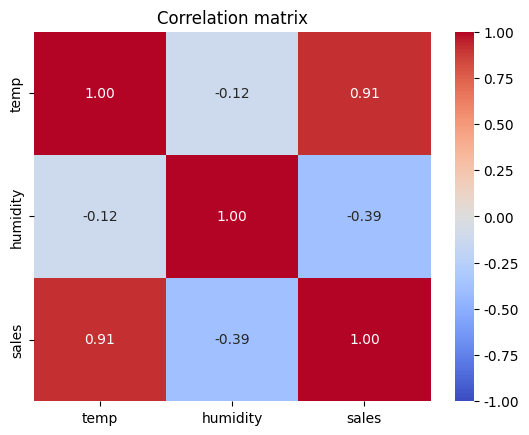

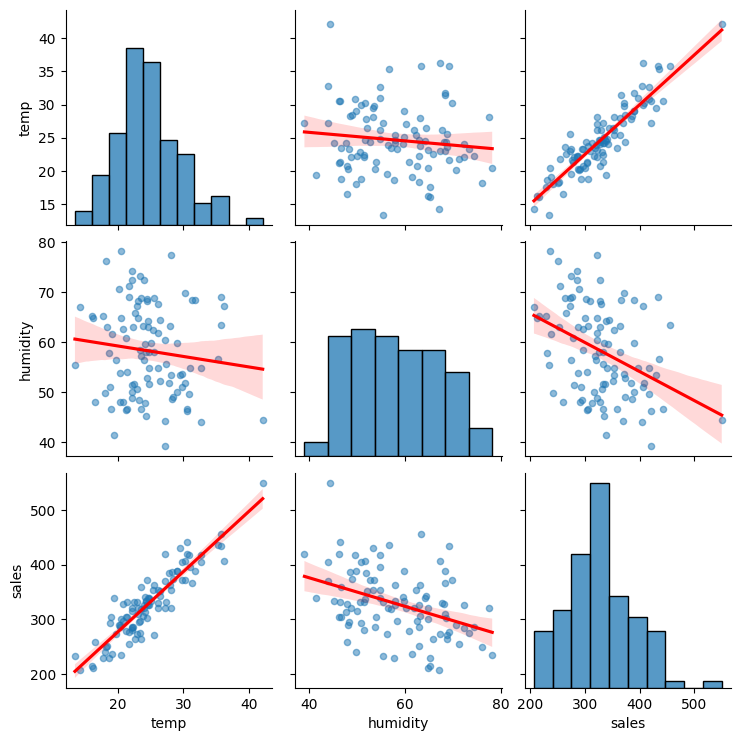

In [14]:
# 아래를 수행해 보세요:
# [문제 6] 여기에 코드를 작성해주세요.

corr = df6.corr()
print(corr.round(2))

import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.show()

sns.pairplot(df6, kind='reg', diag_kind='hist',
             plot_kws={'line_kws': {'color': 'red'},
                       'scatter_kws': {'alpha': 0.5, 's': 20}})
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 출력된 상관계수 행렬을 보고,
   - 어떤 변수와 `sales` 간의 상관계수가 가장 높은가요?
   - 어느 쌍이 **양의 상관관계**, 어느 쌍이 **음의 상관관계**인가요?

2. 페어플롯에서
   - 어떤 변수 쌍은 **직선 형태**로 관계가 보이나요?
   - 어떤 변수 쌍은 **분산이 크거나 패턴이 없는**가요?

3. **상관관계가 반드시 인과관계를 의미하지는 않습니다.**
   - 온도와 매출에 상관관계가 있다고 해서, 온도가 매출을 직접적으로 증가시킨다고 볼 수 있을까요?

4. 이 데이터를 바탕으로 어떤 **추가 가설**이나 **실험 설계**를 생각해볼 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 6] 여기에 의견을 작성해주세요.

1. 출력된 상관계수 행렬을 보고,

▸어떤 변수와 sales 간의 상관계수가 가장 높은가요?
temp(0.91)
▸어느 쌍이 양의 상관관계, 어느 쌍이 음의 상관관계인가요?
temp-sales: 0.91/양의 상관관계
humidity-sales: -0.39/음
humidity-temp: -0.12/음

2. 페어플롯에서

▸어떤 변수 쌍은 직선 형태로 관계가 보이나요?
temp-sales
▸어떤 변수 쌍은 분산이 크거나 패턴이 없는가요?
temp-humidity: 점들이 사방으로 흩어져 있어 패턴이 거의 없다. 
humidity-sales: 방향은 보이지만 흩어짐이 큼

3. 상관관계가 반드시 인과관계를 의미하지는 않습니다.
▸온도와 매출에 상관관계가 있다고 해서, 온도가 매출을 직접적으로 증가시킨다고 볼 수 있을까요?
할 수 없다. 기온과 매출에 동시에 영향을 주는 다른 요인이 있을 수 있기 때문에
ex) 계절과 휴가철, 해가 긴 날, 요일, 행사와 축제

4. 이 데이터를 바탕으로 어떤 추가 가설이나 실험 설계를 생각해볼 수 있을까요?
기온과 습도의 상호작용: 덥고 습한 날(불쾌지수가 높은 날)에는 매출이 단순 합보다 더 크게 줄지 않을까? 회귀식에 temp × humidity 항을 추가해 검증할 수 있습니다.

# 문제 7. 범주형 변수 시각화

**📘 문제**

- 앞에서는 수치형 변수의 분포를 시각화하고, 변수 간의 관계도 살펴보았습니다.
- 이번에는 범주형 변수인 커피 음료 데이터를 시각화해 봅시다.
- 어떤 종류가 많이 판매되었는지 빈도 분석을 통해 알아보겠습니다.

In [15]:
# 데이터 생성
df7 = pd.DataFrame({
    'drink': np.random.choice(['아메리카노', '라떼', '콜드브루'], 300)
})

**📌 아래를 수행해 보세요:**

1. 아래 데이터에서 drink 변수는 판매된 음료의 종류를 나타냅니다.
   - 각각 몇 개씩 판매되었는지 빈도표를 만들어 확인해 봅시다.
   - **막대그래프(bar plot)**를 그려서 결과를 시각화해 봅시다.

2. 시각화 결과를 보고,
   - 어떤 음료가 가장 많이 팔렸는지 파악해 봅시다.
   - 이 결과를 마케팅 전략에 어떻게 활용할 수 있을지 생각해 봅시다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 7] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. 출력된 빈도표와 막대그래프를 보면, 어떤 음료가 가장 많이 판매되었나요?
   - 판매량이 가장 많은 음료는?
   - 그 다음으로 인기 있는 음료는?

2. 이 결과는 어떤 마케팅 전략에 활용할 수 있을까요?
   - 가장 많이 팔린 음료를 주력 상품으로 홍보해야 할까요?
   - 판매량이 적은 음료를 프로모션 대상으로 삼는 것은 어떨까요?

3. 막대그래프는 왜 범주형 변수에 적합할까요?
   - `drink`처럼 종류가 명확히 나뉘는 변수를 분석할 때 어떤 점이 중요한가요?

4. 범주형 변수 분석 시 주의할 점은?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 7] 여기에 의견을 작성해주세요.

# 문제 8. 요일별 평균 비교

**📘 문제**

- 이번에는 요일 별 소비 금액 데이터를 분석해 봅시다.
- 각 요일마다 평균 소비 금액이 얼마나 되는지 비교하고,
  **평일과 주말의 소비 패턴 차이**도 함께 살펴보겠습니다.

In [ ]:
# 데이터 생성
df8 = pd.DataFrame({
    'day': np.random.choice(['월', '화', '수', '목', '금', '토', '일'], 500),
    'amount': np.random.normal(12000, 2000, 500)
})

**📌 아래를 수행해 보세요:**

1. 아래 데이터를 사용하여 `day`(요일)별 `amount`(소비 금액)의 평균을 계산해 봅시다.
2. 요일별 평균 금액을 **막대그래프(bar plot)**로 시각화해 봅시다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 8] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. 어떤 요일에 소비 금액이 가장 높나요?
   - 주말(토, 일)과 평일(월~금) 중 어떤 쪽의 평균이 더 높은가요?

2. 소비 금액이 적은 요일은 언제인가요? 왜 그럴까요?

3. 이 결과를 어떻게 활용할 수 있을까요?
   - 주말에 더 많은 재고를 준비하거나
   - 평일에 할인 이벤트를 기획하는 등의 운영/마케팅 전략으로 이어질 수 있을까요?

---

> 💬 정리해 보기
>
> - 범주형 변수(요일)별로 연속형 변수(소비 금액)의 평균을 비교하면 소비 패턴을 이해하고 전략을 수립하는 데 유용한 인사이트를 얻을 수 있습니다.

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 8] 여기에 의견을 작성해주세요.

# 문제 9. 정규분포와 표준편차

**📘 문제**

- 정규분포와 표준편차의 개념을 실제 데이터에 적용해 보겠습니다.
- 정규분포를 따르는 점수 데이터에서 다음을 확인해 봅시다:
  - 평균 ±1σ, 평균 ±2σ 범위에 속한 값들의 비율은 실제로 얼마나 되는가?
  - 이 결과가 이론적인 68-95-99 법칙과 얼마나 유사한지 비교해 봅시다.

<br>

**📌 아래를 수행해 보세요:**

1. 평균이 70, 표준편차가 10인 정규분포 데이터를 1000개 생성해 봅시다.
2. 평균을 중심으로 ±1σ, ±2σ 범위에 포함되는 데이터의 비율을 계산해 봅시다.
3. 결과를 바탕으로 68-95-99 법칙과 비교해 봅시다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 9] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. ±1σ, ±2σ 범위에 실제로 몇 %의 데이터가 포함되었나요?
2. 이 결과는 68–95–99 법칙과 얼마나 비슷했나요?
3. 표준편차는 왜 중요한 지표인가요?
4. 이 개념이 실제로 어떻게 활용될 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 9] 여기에 의견을 작성해주세요.

# 문제 10. 표본 평균 실험

**📘 문제**

- 큰 모집단에서 표본을 여러 번 추출하여 표본 평균의 분포를 비교해봅시다.

<br>

**📌 아래를 수행해 보세요:**

1. 평균이 100, 표준편차가 15인 모집단을 생성합니다.
2. 다음 두 조건에서 각각 1000번씩 표본 평균을 구합니다:
   - 표본 크기 5
   - 표본 크기 50
3. 두 조건의 **표본 평균 분포(histogram)**를 비교합니다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 10] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. **표본 크기가 다를 때 표본 평균 분포는 어떻게 달라졌나요?**
2. **왜 표본 크기가 중요할까요?**
3. **이 개념은 실제로 어디에 활용될 수 있을까요?**

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 10] 여기에 의견을 작성해주세요.

# 문제 11. 단순 선형 회귀 분석

**📘 문제**

- 공부 시간과 성적 간의 관계를 회귀 분석으로 확인해봅시다.

In [ ]:
# 데이터 생성
from sklearn.linear_model import LinearRegression

np.random.seed(505)
study_time = np.random.normal(5, 2, 100)
score = 50 + study_time * 8 + np.random.normal(0, 5, 100)
df11 = pd.DataFrame({'study_time': study_time, 'score': score})

**📌 아래를 수행해 보세요:**

1. 공부 시간(`study_time`)과 성적(`score`)간의 관계를 단순 선형 회귀모델로 분석합니다.
2. 회귀 모델을 학습하고, 기울기(계수)와 절편을 출력해 봅시다.
3. 산점도 위에 회귀선을 시각화해 봅시다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 11] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. 공부 시간이 성적에 어떤 영향을 주었나요?
2. 회귀선은 데이터를 잘 설명하고 있나요?
3. 이 회귀식을 현실에 적용할 수 있을까요?
4. 선형 회귀분석은 언제 활용할 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 11] 여기에 의견을 작성해주세요.

# 문제 12. A/B 테스트 해석

**📘 문제**

- 두 그룹의 전환율 차이를 계산하고 해석해봅시다.

In [ ]:
# 데이터 생성
np.random.seed(606)
group_a = np.random.binomial(1, 0.12, 1000)
group_b = np.random.binomial(1, 0.15, 1000)

**📌 아래를 수행해 보세요:**

1. A 그룹과 B 그룹의 전환 데이터를 살펴봅니다.
2. 각 그룹의 전환율을 계산하고, 차이를 확인합니다.
3. 이 차이가 우연인지, 의미 있는 차이인지 생각해 봅시다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 12] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. 두 그룹의 전환율 차이는 얼마나 되나요?
2. 차이가 '의미 있다'는 건 무엇을 뜻하나요?
3. 이 실험 결과로 어떤 결정을 내릴 수 있을까요?
4. A/B 테스트는 현실에서 어떻게 쓰일까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 12] 여기에 의견을 작성해주세요.